In [1]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

X_test = np.load("../data/X_test.npy")
y_test = np.load("../data/y_test.npy")
rf_model = joblib.load("../data/rf_model.pkl")

feature_names = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes",
    "land","wrong_fragment","urgent","hot","num_failed_logins","logged_in",
    "num_compromised","root_shell","su_attempted","num_root","num_file_creations",
    "num_shells","num_access_files","num_outbound_cmds","is_host_login",
    "is_guest_login","count","srv_count","serror_rate","srv_serror_rate",
    "rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate",
    "srv_diff_host_rate","dst_host_count","dst_host_srv_count",
    "dst_host_same_srv_rate","dst_host_diff_srv_rate","dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate",
    "dst_host_rerror_rate","dst_host_srv_rerror_rate"
]
print(len(feature_names), X_test.shape)

41 (22544, 41)


src_bytes                      0.195155
dst_bytes                      0.099976
same_srv_rate                  0.081802
dst_host_same_srv_rate         0.068639
flag                           0.066547
dst_host_srv_count             0.065178
logged_in                      0.052530
srv_serror_rate                0.039929
diff_srv_rate                  0.035775
protocol_type                  0.032505
service                        0.028860
count                          0.027901
serror_rate                    0.027347
dst_host_diff_srv_rate         0.027120
dst_host_same_src_port_rate    0.025524
dtype: float64


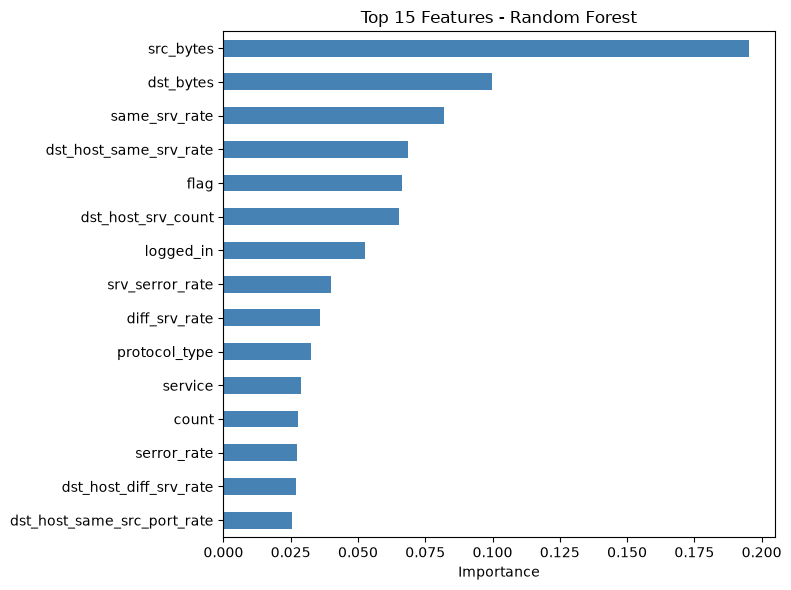

In [2]:
imp = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False)
print(imp.head(15))

imp.head(15)[::-1].plot(kind="barh", figsize=(8,6), color="steelblue")
plt.title("Top 15 Features - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [3]:
proba_attack = rf_model.predict_proba(X_test)[:, 0]   # probability of class 0 = attack
y_attack = (y_test == 0).astype(int)                  # 1 = real attack

rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred_attack = (proba_attack >= t).astype(int)
    rows.append({
        "threshold": t,
        "attack_precision": precision_score(y_attack, pred_attack),
        "attack_recall": recall_score(y_attack, pred_attack),
        "attack_f1": f1_score(y_attack, pred_attack),
    })
pd.DataFrame(rows).round(3)

,threshold,attack_precision,attack_recall,attack_f1
0,0.5,0.966,0.623,0.758
1,0.4,0.967,0.682,0.800
2,0.3,0.966,0.718,0.824
3,0.2,0.964,0.776,0.860
4,0.1,0.927,0.864,0.895


In [4]:
from sklearn.inspection import permutation_importance

idx = np.random.RandomState(42).choice(len(X_test), 3000, replace=False)
r = permutation_importance(rf_model, X_test[idx], y_test[idx],
                           n_repeats=5, random_state=42, n_jobs=-1)
pi = pd.Series(r.importances_mean, index=feature_names).sort_values(ascending=False)
print(pi.head(10))

src_bytes                      0.043333
dst_host_rerror_rate           0.011467
dst_host_same_srv_rate         0.009800
dst_host_srv_count             0.006200
diff_srv_rate                  0.006000
dst_host_srv_diff_host_rate    0.005933
dst_bytes                      0.005600
duration                       0.005200
dst_host_same_src_port_rate    0.004400
rerror_rate                    0.004000
dtype: float64


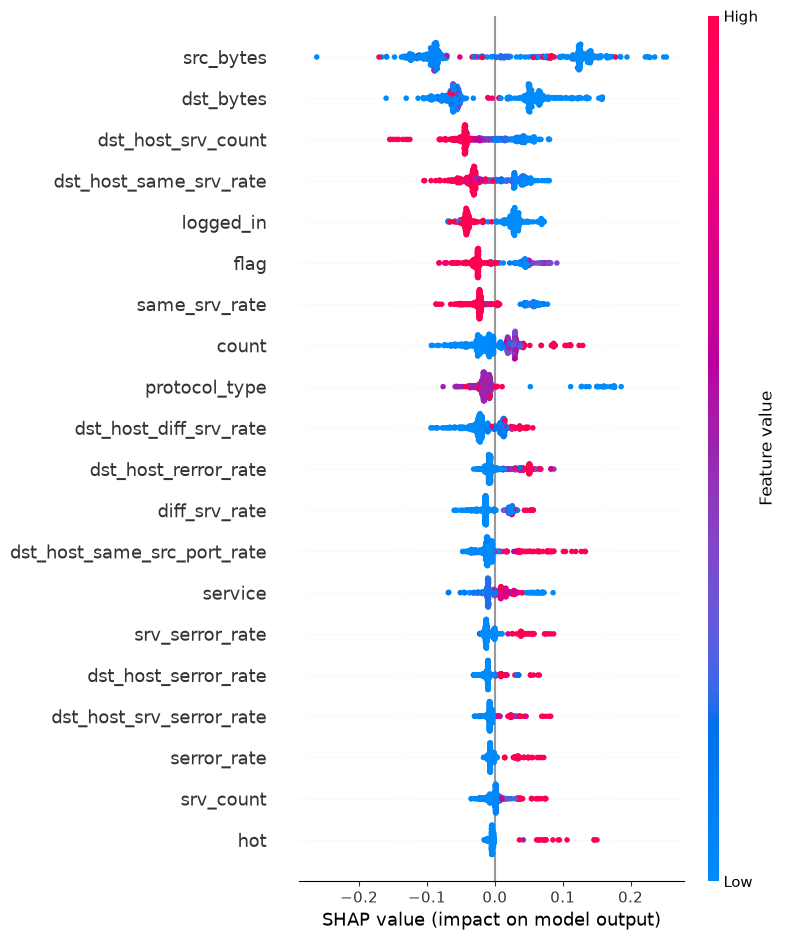

In [5]:
import shap

X_sample = X_test[idx[:500]]
explainer = shap.TreeExplainer(rf_model)
sv = explainer.shap_values(X_sample)

# newer SHAP returns a 3D array, older returns a list: handle both
sv_attack = sv[0] if isinstance(sv, list) else sv[:, :, 0]

shap.summary_plot(sv_attack, X_sample, feature_names=feature_names, show=True)

In [6]:
i = 0
contrib = pd.Series(sv_attack[i], index=feature_names)
print("Model P(attack):", rf_model.predict_proba(X_sample[i:i+1])[0, 0].round(3))
print(contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(8))

Model P(attack): 0.0
src_bytes                -0.093870
dst_bytes                -0.073099
logged_in                -0.054825
flag                     -0.031248
dst_host_same_srv_rate   -0.030371
dst_host_srv_count       -0.024970
count                    -0.023442
same_srv_rate            -0.022951
dtype: float64
